In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
all_pitches = pd.read_csv('../2025_fl_tagged_cleaned/25_ALL_GAMES_cleaned.csv')

C:\Users\215nt\AppData\Local\Temp\ipykernel_41228\3423476985.py:1: DtypeWarning: Columns (27) have mixed types. Specify dtype option on import or set low_memory=False.
  all_pitches = pd.read_csv('../2025_fl_tagged_cleaned/25_ALL_GAMES_cleaned.csv')


In [3]:
all_pitches[['KorBB', 'xDamage', 'xwOBA', 'xSLG']][all_pitches['KorBB'] == 'Strikeout']

,KorBB,xDamage,xwOBA,xSLG
4,Strikeout,NaN,0.0,0.0
9,Strikeout,NaN,0.0,0.0
21,Strikeout,NaN,0.0,0.0
53,Strikeout,NaN,0.0,0.0
82,Strikeout,NaN,0.0,0.0
...,...,...,...,...
247334,Strikeout,NaN,0.0,0.0
247359,Strikeout,NaN,0.0,0.0
247380,Strikeout,NaN,0.0,0.0
247392,Strikeout,NaN,0.0,0.0


(array([27519.,  5733.,  3700.,  2626.,  2167.,  2376.,  2359.,  2447.,
         2533.,  3813.]),
 array([-6.80566714e-16,  1.00000000e-01,  2.00000000e-01,  3.00000000e-01,
         4.00000000e-01,  5.00000000e-01,  6.00000000e-01,  7.00000000e-01,
         8.00000000e-01,  9.00000000e-01,  1.00000000e+00]),
 <BarContainer object of 10 artists>)

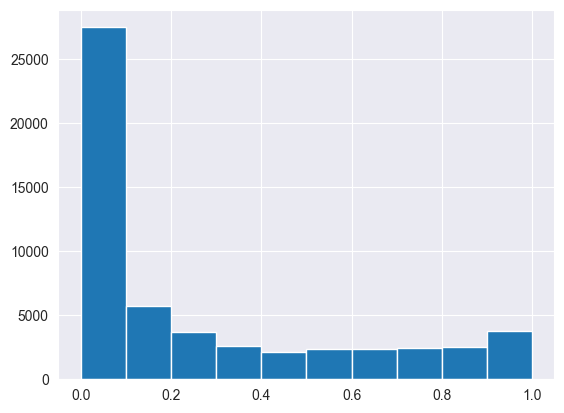

In [4]:
plt.hist(all_pitches['xBA'][all_pitches['xBA'].notna()])

(array([36887.,  7914.,  6489.,  1645.,   740.,   431.,   360.,   269.,
          293.,   245.]),
 array([-4.4408921e-16,  4.0000000e-01,  8.0000000e-01,  1.2000000e+00,
         1.6000000e+00,  2.0000000e+00,  2.4000000e+00,  2.8000000e+00,
         3.2000000e+00,  3.6000000e+00,  4.0000000e+00]),
 <BarContainer object of 10 artists>)

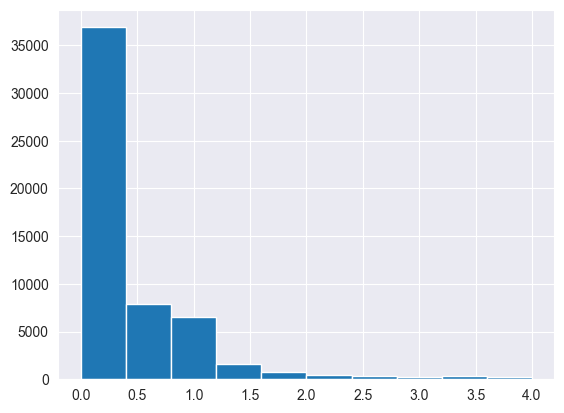

In [5]:
plt.hist(all_pitches['xSLG'][all_pitches['xSLG'].notna()])

In [6]:
np.round(all_pitches[['xBA', 'xSLG']][all_pitches['xSLG'].notna()].describe(), 2)

,xBA,xSLG
count,55273.00,55273.00
mean,0.26,0.40
std,0.32,0.61
min,-0.00,-0.00
25%,0.00,0.00
50%,0.10,0.13
75%,0.49,0.62
max,1.00,4.00


In [7]:
all_pitches['PitchCall'].value_counts()

PitchCall
BallCalled              90379
InPlay                  44149
StrikeCalled            42043
FoulBallNotFieldable    40348
StrikeSwinging          25556
BallinDirt               2298
HitByPitch               1493
FoulBallFieldable         835
BallIntentional           291
AutomaticBall               9
Ballintentional             8
FoulBall                    7
FoulballNotFieldable        1
HItByPitch                  1
Name: count, dtype: int64

In [8]:
all_pitches['PlayResult'].value_counts()

PlayResult
Undefined         203173
Out                26229
Single             10460
Double              2750
HomeRun             1381
FieldersChoice      1140
Sacrifice            989
Error                960
Triple               235
StolenBase            91
CaughtStealing        10
Name: count, dtype: int64

In [9]:
np.mean(all_pitches['Direction'][all_pitches['BatterSide']=="Left"])

np.float64(-26.46640320127207)

In [10]:
np.mean(all_pitches['Direction'][all_pitches['BatterSide']=="Right"])

np.float64(25.729681681992428)

In [11]:
from sklearn.neighbors import NearestNeighbors

In [12]:
def compute_natural_attack_angle(
    df,
    bins=np.linspace(-30, 60, 13),
    top_k=6,
    K=5,
    curvature_threshold=0.0005,
    clamp_range=(-5, 40),
    max_domain=(-10, 45)
):
    """
    Natural_Attack_Angle using:
      - Top-k mean envelope
      - KNN weighting
      - Weighted quadratic fit
      - Three-tier fallback:
            1. Analytic max (preferred)
            2. Frontier fallback (best-supported envelope point)
            3. EV-weighted fallback (tiny or flat envelope)
      - FINAL RULE:
            If the chosen angle hits the clamp, use the empirical max
            ONLY if it has reliable neighbors; otherwise use EV-weighted.
      - Adds: method flag for auditability
    """

    results = []

    for (batter, year), g in df.groupby(["batter", "year"]):

        g = g.dropna(subset=["launch_angle", "launch_speed"])
        bbe = len(g)

        if bbe < 6:
            results.append({
                "batter": batter,
                "year": year,
                "Natural_Attack_Angle": np.nan,
                "Natural_Max_EV": np.nan,
                "BBE": bbe,
                "method": "insufficient_data"
            })
            continue

        g = g.copy()
        g["angle_bin"] = pd.cut(g["launch_angle"], bins=bins, include_lowest=True)

        # Top-k mean envelope (using min(top_k, top 10%))
        envelope_rows = []
        for _, group in g.groupby("angle_bin"):
            if len(group) == 0:
                continue

            k_dynamic = max(1, min(top_k, int(np.ceil(0.65 * len(group)))))

            top = group.nlargest(k_dynamic, "launch_speed")

            envelope_rows.append({
                "launch_angle": top["launch_angle"].mean(),
                "launch_speed": top["launch_speed"].mean()
            })

        top = pd.DataFrame(envelope_rows)

        if len(top) < k_dynamic:
            results.append({
                "batter": batter,
                "year": year,
                "Natural_Attack_Angle": np.nan,
                "Natural_Max_EV": np.nan,
                "BBE": bbe,
                "method": "insufficient_envelope"
            })
            continue
        # Extract x, y
        x = top["launch_angle"].to_numpy(dtype=float).reshape(-1, 1)
        y = top["launch_speed"].to_numpy(dtype=float)

        # KNN weighting
        nbrs = NearestNeighbors(
            n_neighbors=min(K, len(x)),
            algorithm="ball_tree"
        ).fit(x)

        distances, _ = nbrs.kneighbors(x)
        mean_dist = distances.mean(axis=1)

        eps = 1e-6
        weights = 1 / (mean_dist + eps)
        weights = weights / weights.sum()

        # Weighted quadratic fit
        coeffs = np.polyfit(x.flatten(), y, deg=2, w=weights)
        poly = np.poly1d(coeffs)
        a, b, c = coeffs

        # EV-weighted fallback
        ev_weighted_angle = np.average(
            g["launch_angle"],
            weights=g["launch_speed"]
        )

        # Analytic maximum
        analytic_max = -b / (2 * a) if a != 0 else np.nan
        valid_quad = (a < 0) and (abs(a) > curvature_threshold)
        plausible_domain = max_domain[0] <= analytic_max <= max_domain[1]

        # Tier 1: analytic maximum
        if valid_quad and plausible_domain:
            attack_angle = analytic_max
            max_ev = poly(attack_angle)
            method = "analytic_max"

        else:
            # Tier 2: frontier fallback
            best_idx = top["launch_speed"].idxmax()
            frontier_angle = top.loc[best_idx, "launch_angle"]
            frontier_ev = top.loc[best_idx, "launch_speed"]

            envelope_flat = top["launch_speed"].max() - top["launch_speed"].min() < 1.5

            if len(top) < 4 or envelope_flat:
                attack_angle = ev_weighted_angle
                max_ev = g["launch_speed"].max()
                method = "ev_weighted_fallback"
            else:
                attack_angle = frontier_angle
                max_ev = poly(frontier_angle)
                method = "frontier_fallback"

        # FINAL FALLBACK: avoid clamp
        if attack_angle <= clamp_range[0] or attack_angle >= clamp_range[1]:

            # Local support thresholds
            angle_radius = 5.0
            max_angle_spread = 3.0
            max_ev_spread = 2.0
            min_neighbors = 3

            supported_points = []

            # Evaluate local support for every envelope point
            for idx, row in top.iterrows():
                ang = row["launch_angle"]
                ev = row["launch_speed"]

                angle_dist = np.abs(top["launch_angle"] - ang)
                local = top[angle_dist <= angle_radius]

                well_supported = len(local) >= min_neighbors
                angle_coherent = (local["launch_angle"].max() -
                                  local["launch_angle"].min()) <= max_angle_spread
                ev_coherent = (local["launch_speed"].max() -
                               local["launch_speed"].min()) <= max_ev_spread

                if well_supported and angle_coherent and ev_coherent:
                    supported_points.append((ang, ev))

            if supported_points:
                supported_points.sort(key=lambda x: x[1], reverse=True)
                attack_angle, max_ev = supported_points[0]
                method = "clamp_supported_empirical"
            else:
                attack_angle = ev_weighted_angle
                max_ev = g["launch_speed"].max()
                method = "clamp_ev_weighted"

        results.append({
            "batter": batter,
            "year": year,
            "Natural_Attack_Angle": attack_angle,
            "Natural_Max_EV": max_ev,
            "BBE": bbe,
            "method": method
        })

    return pd.DataFrame(results)


In [13]:
def safe_percentile(series, q):
    # Convert to numpy
    vals = series.to_numpy()

    # If object dtype, flatten nested lists/arrays
    if series.dtype == object:
        try:
            vals = np.concatenate([v for v in vals if v is not None and not pd.isna(v)])
        except:
            # fallback: explode and coerce to numeric
            vals = pd.to_numeric(series.explode(), errors='coerce').dropna().to_numpy()
    else:
        vals = series.dropna().to_numpy()

    if len(vals) == 0:
        return np.nan
    if len(vals) == 1:
        return vals[0]

    return np.percentile(vals, q)

In [14]:
def aggregate_hitter_stats_pd(df: pd.DataFrame) -> pd.DataFrame:
    """
    Full hitter aggregation including:
      - Plate discipline
      - Contact quality
      - Expected stats
      - Zone contact
      - HR/AB
      - PullAirPct (physics + BatterSide aware)
      - ISO, BABIP, OPS
      - Natural_Attack_Angle + Natural_Max_EV (merged from compute_natural_attack_angle)
    """

    # Ensure Date is datetime
    if not np.issubdtype(df["Date"].dtype, np.datetime64):
        df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

    # Extract Year for NAA computation
    df["Year"] = df["Date"].dt.year

    # Patch PlayResult using KorBB where appropriate
    df["PlayResult"] = df["PlayResult"].mask(
        df["KorBB"].isin(["Strikeout", "Walk"]),
        df["KorBB"]
    )

    # Plate appearance definition (exclude Undefined, SB, CS)
    invalid_pa = ["Undefined", "StolenBase", "CaughtStealing"]
    df["is_pa"] = ~df["PlayResult"].isin(invalid_pa)

    # At-bat definition
    invalid_ab = ["Undefined", "StolenBase", "CaughtStealing", "Sacrifice", "Walk"]
    df["is_ab"] = ~df["PlayResult"].isin(invalid_ab)

    # -------------------------
    # Outcome + Batted Ball Flags
    # -------------------------
    df = df.assign(
        # Swing outcomes
        is_swing = df["Swing"] == 1,
        is_whiff = df["Whiff"] == 1,
        is_chase = df["Chase"] == 1,
        is_foul = df["PitchCall"].str.contains("Foul"),
        is_in_play = df["PitchCall"] == "InPlay",
        is_strike_called = df["PitchCall"] == "StrikeCalled",
        is_strike_swinging = df["PitchCall"] == "StrikeSwinging",

        # PA outcomes
        is_strikeout = df["PlayResult"] == "Strikeout",
        is_walk = df["PlayResult"] == "Walk",
        is_hr = df["PlayResult"] == "HomeRun",

        # Hit-type flags
        is_single = df["PlayResult"] == "Single",
        is_double = df["PlayResult"] == "Double",
        is_triple = df["PlayResult"] == "Triple",

        # Zone-based flags
        is_in_zone = df["OutsideZone"] == 0,
        in_zone_swing = (df["Swing"] == 1) & (df["OutsideZone"] == 0),
        in_zone_contact = (df["Swing"] == 1) & (df["Whiff"] == 0) & (df["OutsideZone"] == 0),

        # Batted ball definition
        is_bbe = df["PitchCall"] == "InPlay",

        # Physics-based air ball
        is_air = df["Angle"] >= 10,

        is_ground = df['Angle'] < 10,
        is_line_drive = ((df['Angle'] >= 10) & (df['Angle'] <= 25)),
        is_fly_ball = (df['Angle'] > 25) & (df['Angle'] <= 50),
        is_pop_up = df['Angle'] > 50,

        # BatterSide-aware pull logic
        is_pull = np.where(
            df["BatterSide"] == "Right",
            df["Direction"] >= 10,
            np.where(
                df["BatterSide"] == "Left",
                df["Direction"] <= -10,
                False
            )
        ),

        # Pulled Air Ball
        is_pull_air = (
            (df["PitchCall"] == "InPlay") &
            df["ExitSpeed"].notna() &
            (df["Angle"] >= 10) &
            np.where(
                df["BatterSide"] == "Right",
                df["Direction"] >= 10,
                np.where(
                    df["BatterSide"] == "Left",
                    df["Direction"] <= -10,
                    False
                )
            )
        ),
        is_sweet_spot = ((df["PitchCall"] == "InPlay") & (df['Angle'] >= 8) & (df['Angle'] <= 32)),
        is_barrel = ((df['xBA'] >= .500) & (df['xSLG'] >= 1.500)),
    )


    # -------------------------
    # 1. Compute Natural Attack Angle per batter-year
    # -------------------------
    naa_input = df.rename(columns={
        "Batter": "batter",
        "BatterTeam": "team",
        "Angle": "launch_angle",
        "ExitSpeed": "launch_speed",
        "Year": "year"
    })

    naa_df = compute_natural_attack_angle(naa_input)

    naa_df = naa_df.rename(columns={
        "batter": "Batter",
        "year": "Year",
        "Natural_Attack_Angle": "natural_attack_angle",
        "Natural_Max_EV": "natural_max_ev",
        "method": "natural_method"
    })

    # -------------------------
    # 2. Aggregate hitter-level stats
    # -------------------------
    grouped = df.groupby(["Batter", "BatterTeam"])

    agg = pd.DataFrame({
        "pitches_seen": grouped.size(),
        "swings": grouped["is_swing"].sum(),
        "whiffs": grouped["is_whiff"].sum(),
        "chase_swings": grouped["is_chase"].sum(),
        "foul_balls": grouped["is_foul"].sum(),
        "balls_in_play": grouped["is_in_play"].sum(),
        "called_strikes": grouped["is_strike_called"].sum(),
        "swinging_strikes": grouped["is_strike_swinging"].sum(),
        "zone_rate": grouped['is_in_zone'].sum()/grouped.size(),

        # Rates
        "swing_rate": grouped["is_swing"].mean(),
        "whiff_rate": grouped["is_whiff"].sum() / grouped["is_swing"].sum(),
        "chase_rate": grouped["is_chase"].sum() / (grouped.size() - grouped["is_in_zone"].sum()),
        "in_play_rate": grouped["is_in_play"].sum() / grouped["is_swing"].sum(),
        "contact_rate": (grouped["is_swing"].sum() - grouped["is_whiff"].sum()) / grouped["is_swing"].sum(),
        "sweet_spot_rate": grouped['is_sweet_spot'].sum() / grouped['is_in_play'].sum(),
        "gb_rate": grouped['is_ground'].sum() / grouped['is_in_play'].sum(),
        "ld_rate": grouped['is_line_drive'].sum() / grouped['is_in_play'].sum(),
        "fb_rate": grouped['is_fly_ball'].sum() / grouped['is_in_play'].sum(),
        "pu_rate": grouped['is_pop_up'].sum() / grouped['is_in_play'].sum(),

        # Zone contact
        "zone_swings": grouped["in_zone_swing"].sum(),
        "zone_swing_rate" : (grouped['in_zone_swing'].sum())/(grouped['is_in_zone'].sum()),
        "zone_contact": grouped["in_zone_contact"].sum(),
        "zone_contact_rate": grouped["in_zone_contact"].sum() / grouped["in_zone_swing"].sum(),

        # Quality of contact
        "avg_exit_velo": grouped["ExitSpeed"].mean(),
        "avg_launch_angle": grouped["Angle"].mean(),
        "avg_direction": grouped["Direction"].mean(),
        "avg_batspeed": grouped["batspeed"].mean(),
        "max_ev": grouped.apply(lambda g: g.loc[(g["Angle"] >= -30) & (g["Angle"] <= 30), "ExitSpeed"].max()),
        "ev_95": grouped["ExitSpeed"].apply(lambda x: safe_percentile(x, 95)),
        "ev_90": grouped["ExitSpeed"].apply(lambda x: safe_percentile(x, 90)),
        "ev_70": grouped["ExitSpeed"].apply(lambda x: safe_percentile(x, 70)),
        "barrel_rate": grouped["is_barrel"].sum() / grouped["is_in_play"].sum(),

        # Expected stats
        "xDamage": grouped["xDamage"].mean(),
        "xwOBA": grouped["xwOBA"].mean(),
        "xSLG": grouped["xSLG"].mean(),
        "xBA": grouped["xBA"].mean(),

        # Plate appearance outcomes
        "plate_appearances": grouped["is_pa"].sum(),
        "strikeouts": grouped["is_strikeout"].sum(),
        "walks": grouped["is_walk"].sum(),

        # Rates
        "strikeout_rate": grouped["is_strikeout"].sum() / grouped["is_pa"].sum(),
        "walk_rate": grouped["is_walk"].sum() / grouped["is_pa"].sum(),

        # HR / AB
        "home_runs": grouped["is_hr"].sum(),
        "at_bats": grouped["is_ab"].sum(),
        "hr_per_ab": grouped["is_hr"].sum() / grouped["is_ab"].sum(),

        # Hit components
        "singles": grouped["is_single"].sum(),
        "doubles": grouped["is_double"].sum(),
        "triples": grouped["is_triple"].sum(),
        "hits": (
            grouped["is_single"].sum()
            + grouped["is_double"].sum()
            + grouped["is_triple"].sum()
            + grouped["is_hr"].sum()
        ),

        # Total bases
        "total_bases": (
            grouped["is_single"].sum()
            + 2 * grouped["is_double"].sum()
            + 3 * grouped["is_triple"].sum()
            + 4 * grouped["is_hr"].sum()
        ),

        # ISO = (TB - H) / AB
        "iso": (
            (
                grouped["is_single"].sum()
                + 2 * grouped["is_double"].sum()
                + 3 * grouped["is_triple"].sum()
                + 4 * grouped["is_hr"].sum()
                - (
                    grouped["is_single"].sum()
                    + grouped["is_double"].sum()
                    + grouped["is_triple"].sum()
                    + grouped["is_hr"].sum()
                )
            )
            / grouped["is_ab"].sum()
        ),

        # BABIP = (H - HR) / (AB - K - HR + SF)
        # You don't have Sac Flies, so we omit SF

        "tto_rate" : (
            (grouped["is_hr"].sum()
             + grouped["is_walk"].sum()
             + grouped["is_strikeout"].sum()
             )
            / grouped["is_pa"].sum()
        ),
        "avg" : (
            (
            grouped["is_single"].sum()
            + grouped["is_double"].sum()
            + grouped["is_triple"].sum()
            + grouped["is_hr"].sum()
            )
            /
            grouped["is_ab"].sum()
        ),
        "babip": (
            (
                grouped["is_single"].sum()
                + grouped["is_double"].sum()
                + grouped["is_triple"].sum()
            )
            / (
                grouped["is_ab"].sum()
                - grouped["is_strikeout"].sum()
                - grouped["is_hr"].sum()
            )
        ),

        # OPS = OBP + SLG
        # OBP = (H + BB) / PA
        "obp": (
            (
                grouped["is_single"].sum()
                + grouped["is_double"].sum()
                + grouped["is_triple"].sum()
                + grouped["is_hr"].sum()
                + grouped["is_walk"].sum()
            )
            / grouped["is_pa"].sum()
        ),

        # SLG = TB / AB
        "slg": (
            (
                grouped["is_single"].sum()
                + 2 * grouped["is_double"].sum()
                + 3 * grouped["is_triple"].sum()
                + 4 * grouped["is_hr"].sum()
            )
            / grouped["is_ab"].sum()
        ),

        "ops": (
            (
                (
                    grouped["is_single"].sum()
                    + grouped["is_double"].sum()
                    + grouped["is_triple"].sum()
                    + grouped["is_hr"].sum()
                    + grouped["is_walk"].sum()
                )
                / grouped["is_pa"].sum()
            )
            +
            (
                (
                    grouped["is_single"].sum()
                    + 2 * grouped["is_double"].sum()
                    + 3 * grouped["is_triple"].sum()
                    + 4 * grouped["is_hr"].sum()
                )
                / grouped["is_ab"].sum()
            )
        ),

        # PullAirPct
        "pull_air_bbe": grouped["is_pull_air"].sum(),
        "total_bbe": grouped["is_bbe"].sum(),
        "pull_air_pct": grouped["is_pull_air"].sum() / grouped["is_bbe"].sum(),
    }).reset_index()

    # -------------------------
    # 3. Merge Natural Attack Angle back in
    # -------------------------
    agg = agg.merge(
        naa_df[["Batter", "Year", "natural_attack_angle", "natural_max_ev", "natural_method"]],
        on="Batter",
        how="left"
    )

    return agg


In [15]:
all_pitches['xwOBA'][all_pitches['Batter'] == "Acevedo, Luis"].mean()

np.float64(0.3539993055555555)

In [16]:
hitter_agg = aggregate_hitter_stats_pd(all_pitches)

C:\Users\215nt\AppData\Local\Temp\ipykernel_41228\4002418909.py:48: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for _, group in g.groupby("angle_bin"):
C:\Users\215nt\AppData\Local\Temp\ipykernel_41228\4002418909.py:48: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for _, group in g.groupby("angle_bin"):
C:\Users\215nt\AppData\Local\Temp\ipykernel_41228\4002418909.py:48: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fo

In [17]:
hitter_agg.to_parquet('hitter_agg.parquet')

In [18]:
hitter_agg.head()

,Batter,BatterTeam,pitches_seen,swings,whiffs,chase_swings,foul_balls,balls_in_play,called_strikes,swinging_strikes,...,obp,slg,ops,pull_air_bbe,total_bbe,pull_air_pct,Year,natural_attack_angle,natural_max_ev,natural_method
0,"Abbot, Sam",Ottawa Titans,21,5,3,1,2,0,8,3,...,0.250000,0.000000,0.250000,0,0,NaN,2025.0,NaN,NaN,insufficient_data
1,"Abbott, Sam",Ottawa Titans,245,101,35,22,36,30,38,35,...,0.350877,0.282609,0.633486,6,30,0.200000,2025.0,15.904762,93.582215,analytic_max
2,"Acevedo, Luis",New Jersey Jackals,1033,415,57,62,130,228,224,57,...,0.375427,0.396078,0.771505,32,228,0.140351,2025.0,6.422128,100.159929,analytic_max
3,"Acevedo, Luis",Tri-City ValleyCats,1,1,0,0,1,0,0,0,...,NaN,NaN,NaN,0,0,NaN,2025.0,6.422128,100.159929,analytic_max
4,"Adams, Christian",Down East Bird Dawgs,210,106,37,14,38,31,26,37,...,0.351852,0.510638,0.862490,8,31,0.258065,2025.0,26.943383,104.756470,clamp_ev_weighted


In [19]:
hitter_agg['ev_90'].describe()

count    445.000000
mean      95.659582
std        7.016211
min       54.662990
25%       93.732478
50%       97.223134
75%       99.734815
max      108.930046
Name: ev_90, dtype: float64

In [20]:
hitter_agg['ev_70'].describe()

count    445.000000
mean      87.268230
std        6.067934
min       54.662990
25%       84.638720
50%       88.330784
75%       91.190064
max      105.938912
Name: ev_70, dtype: float64

In [21]:
hitter_agg[hitter_agg['Batter'] == "Corliss, Craig"]

,Batter,BatterTeam,pitches_seen,swings,whiffs,chase_swings,foul_balls,balls_in_play,called_strikes,swinging_strikes,...,obp,slg,ops,pull_air_bbe,total_bbe,pull_air_pct,Year,natural_attack_angle,natural_max_ev,natural_method
92,"Corliss, Craig",Joliet Slammers,86,44,12,12,19,13,10,12,...,0.347826,0.210526,0.558352,3,13,0.230769,2025.0,17.376486,80.475578,frontier_fallback
93,"Corliss, Craig",Windy City ThunderBolts,143,56,17,12,18,21,36,17,...,0.222222,0.187500,0.409722,5,21,0.238095,2025.0,17.376486,80.475578,frontier_fallback


In [22]:
def weighted_corr(df, x, y, w):
    d = df[[x, y, w]].dropna().copy()

    # Remove zero-weight rows
    d = d[d[w] > 0]

    if d.empty:
        raise ValueError("No valid rows after filtering zero weights and NaNs.")

    x = d[x].to_numpy()
    y = d[y].to_numpy()
    w = d[w].to_numpy()

    w_sum = w.sum()
    mx = (w * x).sum() / w_sum
    my = (w * y).sum() / w_sum

    cov_xy = (w * (x - mx) * (y - my)).sum()
    var_x = (w * (x - mx)**2).sum()
    var_y = (w * (y - my)**2).sum()

    if var_x == 0 or var_y == 0:
        raise ValueError("Weighted variance is zero — correlation undefined.")

    return cov_xy / np.sqrt(var_x * var_y)



In [23]:
corr = weighted_corr(hitter_agg, "whiff_rate", "strikeout_rate", "plate_appearances")
corr


np.float64(0.8475566551222808)

In [24]:
corr = weighted_corr(hitter_agg, "chase_rate", "walk_rate", "plate_appearances")
corr

np.float64(-0.6952493330674901)

In [25]:
corr = weighted_corr(hitter_agg[hitter_agg['BatterTeam'] == "Windy City ThunderBolts"], "whiff_rate", "strikeout_rate", "plate_appearances")
corr

np.float64(0.8232997605118078)

In [26]:
corr = weighted_corr(hitter_agg, "zone_contact_rate", "strikeout_rate", "plate_appearances")
corr

np.float64(-0.7935405731157944)

In [27]:
corr = weighted_corr(hitter_agg, "chase_rate", "walk_rate", "plate_appearances")
corr

np.float64(-0.6952493330674901)

In [28]:
corr = weighted_corr(hitter_agg, "zone_contact_rate", "whiff_rate", "plate_appearances")
corr

np.float64(-0.9248044261213556)

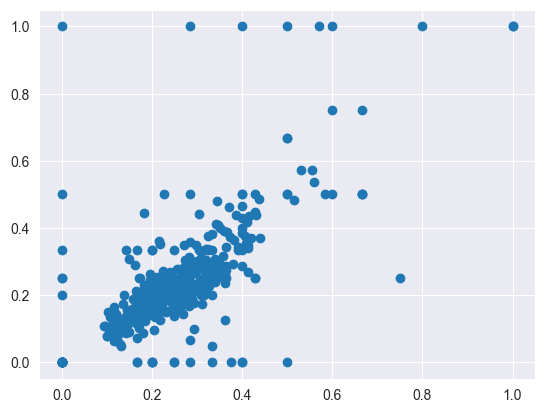

In [29]:
plt.scatter(hitter_agg['whiff_rate'], hitter_agg['strikeout_rate'])